# 2 · A borehole model you can trust: MODFLOW 6 checked against the Dalem test

**KAI Water & Energy case studies** · [Interactive version on the KAI platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free)

An analytic model (notebook 1) answers questions about one borehole in an endless, uniform aquifer. Real
wellfields have several boreholes, schedules and boundaries, and need a numerical model. The rule we follow
at KAI: **before a model is used to plan anything, it must reproduce a real measurement.**

Here you will:

1. build a one-layer MODFLOW 6 model (through [FloPy](https://github.com/modflowpy/flopy)) of the Dalem aquifer,
   with leakage from the layer above;
2. run the real 8-hour Dalem pumping test in it and compare with the field readings *and* with TTim;
3. only then ask a planning question: two boreholes 250 m apart, 1,500 m³/day each, for a year.

You need the `mf6` executable. Install it once with `get-modflow :flopy`, or set the `MF6` environment
variable to its path. Runtime: about two minutes.

In [1]:
import contextlib
import io
import json
import os
import shutil
import warnings
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ttim
from scipy.interpolate import RegularGridInterpolator

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

def find_mf6():
    for cand in (os.environ.get("MF6"), shutil.which("mf6"), str(Path.home() / ".local/share/flopy/bin/mf6")):
        if cand and Path(cand).exists():
            return cand
    raise FileNotFoundError("mf6 not found: run `get-modflow :flopy` or set MF6=/path/to/mf6")

MF6 = find_mf6()
WORK = Path("work"); WORK.mkdir(exist_ok=True)
import subprocess
print("FloPy", flopy.__version__, "| MODFLOW", " ".join(subprocess.run([MF6, "--version"], capture_output=True, text=True).stdout.split()[1:3]))

FloPy 3.11.0 | MODFLOW 6.7.0 02/05/2026


## Step 1 · The aquifer, from the pumping test

We repeat the TTim fit of notebook 1 for Dalem (a few seconds) so this notebook stands on its own.

In [2]:
obs = {}
for r in (30, 60, 90, 120):
    a = np.loadtxt(f"data/pumping-tests/dalem_p{r}.txt", skiprows=1)
    obs[r] = (a[:, 0], a[:, 1])                      # days, head change (m)

Q, Z, RW, T_STOP = 761.0, [0.0, -8.0, -45.0], 0.1, 0.34
ml = ttim.ModelMaq(kaq=10, z=Z, c=500, Saq=1e-4, topboundary="semi", tmin=1e-5, tmax=12)
ttim.Well(ml, xw=0, yw=0, rw=RW, tsandQ=[(0, Q), (T_STOP, 0)], layers=0)
ml.solve(silent=True)
ca = ttim.Calibrate(ml)
ca.set_parameter(name="kaq0", initial=10); ca.set_parameter(name="Saq0", initial=1e-4); ca.set_parameter(name="c0", initial=500, pmin=0)
for r, (t, h) in obs.items():
    ca.series(name=f"r{r}", x=r, y=0, t=t, h=h, layer=0)
with contextlib.redirect_stdout(io.StringIO()):
    ca.fit(report=False)
K, SS, C = ca.parameters["optimal"].to_numpy(float)
TOP, BOT = -8.0, -45.0
print(f"k = {K:.1f} m/day, Ss = {SS:.2e} 1/m, c = {C:.0f} days  →  T = {K * (TOP - BOT):.0f} m²/day")

k = 45.3 m/day, Ss = 4.76e-05 1/m, c = 331 days  →  T = 1677 m²/day


## Step 2 · The MODFLOW 6 model

One model layer for the aquifer. The leaky layer above is a **general-head boundary** in every cell: water
flows in at a rate of (head above − head in the aquifer) × cell area / *c*, which is exactly the Hantush
assumption TTim makes. Cells are 1 m wide at the borehole and grow by 15 % per cell up to 250 m, out to 5 km,
so the cone of depression is resolved without millions of cells.

In [3]:
def edges(focus, dmin=1.0, growth=1.15, dmax=250.0, extent=5000.0):
    """Cell edges along one axis: small cells at each focus point, growing geometrically away from them."""
    focus = sorted(focus)
    size = lambda x: min(dmax, max(dmin, dmin + (growth - 1.0) * min(abs(x - f) for f in focus)))
    right, left = [focus[0] + dmin / 2], [focus[0] - dmin / 2]
    while right[-1] < focus[-1] + extent:
        right.append(right[-1] + size(right[-1]))
    while left[-1] > focus[0] - extent:
        left.append(left[-1] - size(left[-1]))
    return np.array(left[::-1] + right)


def run_model(name, wells, periods, rates):
    """wells: [(x, y)]; periods: [(length days, n steps, multiplier)]; rates[p][w]: m³/day pumped."""
    ex, ey = edges([w[0] for w in wells]), edges([w[1] for w in wells])
    delr, delc = np.diff(ex), np.diff(ey)[::-1]          # MODFLOW rows run north to south
    nrow, ncol = len(delc), len(delr)
    ws = WORK / name
    sim = flopy.mf6.MFSimulation(sim_name=name, sim_ws=str(ws), exe_name=MF6, verbosity_level=0)
    flopy.mf6.ModflowTdis(sim, nper=len(periods), perioddata=periods, time_units="days")
    flopy.mf6.ModflowIms(sim, complexity="simple", outer_dvclose=1e-7, inner_dvclose=1e-8)
    gwf = flopy.mf6.ModflowGwf(sim, modelname=name, save_flows=True)
    flopy.mf6.ModflowGwfdis(gwf, nlay=1, nrow=nrow, ncol=ncol, delr=delr, delc=delc, top=TOP, botm=[BOT])
    flopy.mf6.ModflowGwfnpf(gwf, icelltype=0, k=K)
    flopy.mf6.ModflowGwfsto(gwf, iconvert=0, ss=SS, transient={0: True})
    flopy.mf6.ModflowGwfic(gwf, strt=0.0)                 # heads are changes from the start level
    area = np.outer(delc, delr)
    flopy.mf6.ModflowGwfghb(gwf, stress_period_data={0: [[(0, i, j), 0.0, area[i, j] / C] for i in range(nrow) for j in range(ncol)]})
    cell = lambda x, y: (0, nrow - 1 - int(np.searchsorted(ey, y) - 1), int(np.searchsorted(ex, x) - 1))
    flopy.mf6.ModflowGwfwel(gwf, stress_period_data={p: [[cell(*w), -rates[p][i]] for i, w in enumerate(wells)] for p in range(len(periods))})
    flopy.mf6.ModflowGwfoc(gwf, head_filerecord=f"{name}.hds", budget_filerecord=f"{name}.cbc", saverecord=[("HEAD", "ALL"), ("BUDGET", "ALL")])
    sim.write_simulation(silent=True)
    ok, _ = sim.run_simulation(silent=True)
    assert ok, "MODFLOW 6 did not converge"
    hds = gwf.output.head()
    times = np.array(hds.get_times())
    heads = np.array([hds.get_data(totim=t)[0][::-1, :] for t in times])   # flip to south → north
    xc, yc = (ex[:-1] + ex[1:]) / 2, (ey[:-1] + ey[1:]) / 2
    at = lambda x, y: np.array([RegularGridInterpolator((yc, xc), h)([[y, x]])[0] for h in heads])
    return dict(times=times, heads=heads, x=xc, y=yc, at=at, gwf=gwf, ncells=nrow * ncol)

## Step 3 · Reproduce the real test

Pump 761 m³/day for 0.34 days, then stop, and read the model at 30, 60, 90 and 120 m.

11,449 cells


distance (m),"MODFLOW vs field (mm, RMSE)","MODFLOW vs TTim (mm, max)"
30,4.8,0.5
60,9.2,0.4
90,1.4,0.5
120,5.6,0.5


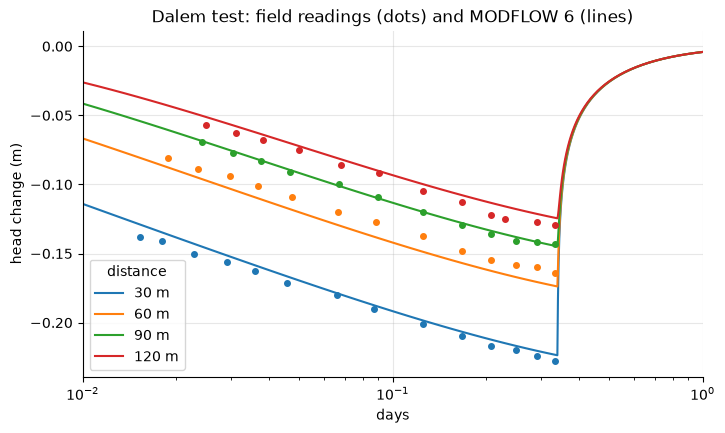

In [4]:
test = run_model("dalem_test", [(0.0, 0.0)], [(0.34, 60, 1.08), (0.66, 40, 1.1)], [[Q], [0.0]])
print(f"{test['ncells']:,} cells")

def ttim_head(r, t):
    m = ttim.ModelMaq(kaq=K, z=Z, c=C, Saq=SS, topboundary="semi", tmin=1e-5, tmax=2)
    ttim.Well(m, xw=0, yw=0, rw=RW, tsandQ=[(0, Q), (T_STOP, 0)], layers=0)
    m.solve(silent=True)
    return m.head(r, 0, t)[0]

rows = []
fig, ax = plt.subplots()
for i, (r, (t, h)) in enumerate(obs.items()):
    sim = np.interp(t, test["times"], test["at"](r, 0.0))
    rows.append({"distance (m)": r, "MODFLOW vs field (mm, RMSE)": np.sqrt(np.mean((sim - h) ** 2)) * 1000,
                 "MODFLOW vs TTim (mm, max)": np.abs(sim - ttim_head(r, t)).max() * 1000})
    ax.semilogx(t, h, "o", ms=4, color=f"C{i}")
    ax.semilogx(test["times"], test["at"](r, 0.0), "-", color=f"C{i}", label=f"{r} m")
ax.set(title="Dalem test: field readings (dots) and MODFLOW 6 (lines)", xlabel="days", ylabel="head change (m)", xlim=(0.01, 1))
ax.legend(title="distance")
pd.DataFrame(rows).style.format(precision=1).hide(axis="index")

The numerical model reproduces the field readings to within millimetres, and agrees with the analytic
solution to well under a millimetre. Only now do we use it to plan.

## Step 4 · What if: two boreholes 250 m apart

Two new boreholes in this aquifer, 250 m apart, each pumping 1,500 m³/day for a year. How far does each one
draw down, how much of that is caused by its neighbour, and where does the water come from?

*The drawdown read here is the aquifer drawdown in the 1 m model cell that holds the borehole. The level inside
a real borehole is lower still: add the radius correction (Thiem/Peaceman, of the order of 0.1 m here) and the
well's own losses, which a step test measures.*

After a year: 1.38 m aquifer drawdown at each borehole cell; 1.20 m if it pumped alone; 13% of it comes from the neighbour.


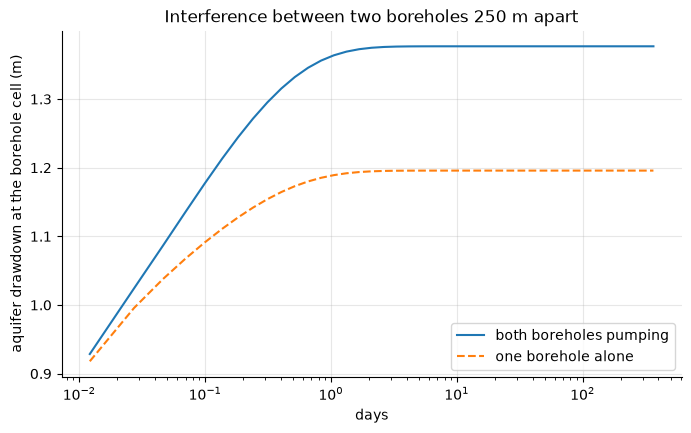

In [5]:
q, half = 1500.0, 125.0
wells = [(-half, 0.0), (half, 0.0)]
both = run_model("two_wells", wells, [(365.0, 40, 1.25)], [[q, q]])
alone = run_model("one_well", wells[:1], [(365.0, 40, 1.25)], [[q]])
s_both, s_alone = -both["at"](*wells[0]), -alone["at"](*wells[0])
print(f"After a year: {s_both[-1]:.2f} m aquifer drawdown at each borehole cell; {s_alone[-1]:.2f} m if it pumped alone; "
      f"{(s_both[-1] - s_alone[-1]) / s_both[-1]:.0%} of it comes from the neighbour.")

fig, ax = plt.subplots()
ax.semilogx(both["times"], s_both, label="both boreholes pumping")
ax.semilogx(alone["times"], s_alone, "--", label="one borehole alone")
ax.set(xlabel="days", ylabel="aquifer drawdown at the borehole cell (m)", title="Interference between two boreholes 250 m apart")
ax.legend();

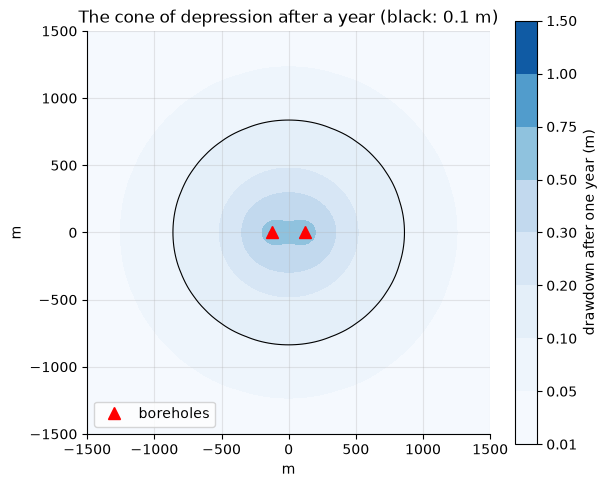

In [6]:
grid = np.linspace(-1500, 1500, 121)
yy, xx = np.meshgrid(grid, grid, indexing="ij")
f = RegularGridInterpolator((both["y"], both["x"]), -both["heads"][-1])
smap = f(np.stack([yy.ravel(), xx.ravel()], axis=1)).reshape(yy.shape)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cs = ax.contourf(xx, yy, smap, levels=[0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5], cmap="Blues")
ax.contour(xx, yy, smap, levels=[0.1], colors="k", linewidths=0.8)
ax.plot(*zip(*wells), "r^", ms=9, label="boreholes")
fig.colorbar(cs, label="drawdown after one year (m)")
ax.set(aspect="equal", xlabel="m", ylabel="m", title="The cone of depression after a year (black: 0.1 m)")
ax.legend(loc="lower left");

## Where does the water come from?

At first the water comes out of storage in the aquifer; soon almost all of it leaks down from the layer above.
The cell-by-cell budget shows when.

95 % of the water comes from the layer above after 2.1 days


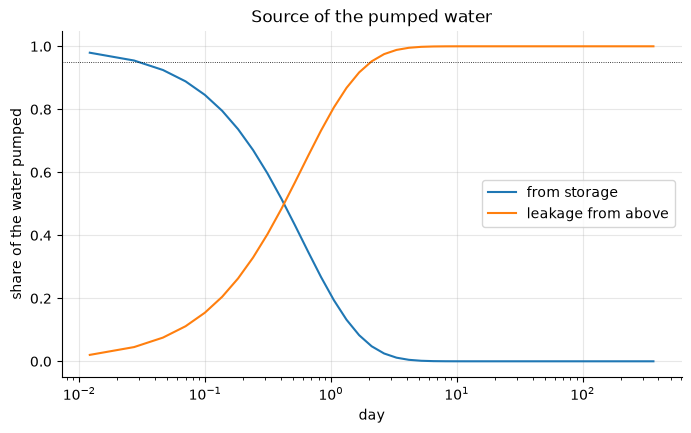

In [7]:
cbc = both["gwf"].output.budget()
rows = []
for t in both["times"]:
    get = lambda text: sum(float(np.sum(r["q"]) if r.dtype.names else np.sum(r)) for r in cbc.get_data(text=text, totim=t))
    rows.append({"day": t, "from storage": get("STO-SS") / (2 * q), "leakage from above": get("GHB") / (2 * q)})
src = pd.DataFrame(rows).set_index("day")
ax = src.plot(logx=True, ylabel="share of the water pumped", title="Source of the pumped water")
ax.axhline(0.95, color="k", lw=0.6, ls=":")
t95 = src.index[src["leakage from above"] >= 0.95][0]
print(f"95 % of the water comes from the layer above after {t95:.1f} days")

In [8]:
kai = json.loads(Path("results/kai_engine_results.json").read_text())["mf6"]
w = kai["whatif"]
assert abs(s_both[-1] - w["borehole_drawdown_m"]) < 0.02, "drawdown differs from the published KAI result"
pd.DataFrame([
    {"result": "aquifer drawdown at each borehole cell after a year (m)", "this notebook": s_both[-1], "KAI engine": w["borehole_drawdown_m"]},
    {"result": "same, one borehole alone (m)", "this notebook": s_alone[-1], "KAI engine": w["alone_drawdown_m"]},
    {"result": "share caused by the neighbour", "this notebook": (s_both[-1] - s_alone[-1]) / s_both[-1], "KAI engine": w["interference_share"]},
    {"result": "days until 95 % of the water leaks from above", "this notebook": t95, "KAI engine": w["days_to_95pct_leakage"]},
]).style.format({"this notebook": "{:.2f}", "KAI engine": "{:.2f}"}).hide(axis="index")

result,this notebook,KAI engine
aquifer drawdown at each borehole cell after a year (m),1.38,1.38
"same, one borehole alone (m)",1.20,1.20
share caused by the neighbour,0.13,0.13
days until 95 % of the water leaks from above,2.11,2.11


The notebook and the engine agree (the engine's published run used MODFLOW 6.6.0; this notebook may run a newer
release, with the same results). In an operating park, the next step is to put the real boreholes, pumping schedules and
boundaries in this model and keep it current with logger data: that is what HydroSaaS does.

---

**On the KAI platform**

* [Borehole case, interactive](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes), including the drawdown map and the yield table.
* [HydroSaaS demo park: demand and boreholes](https://hydro-saas.charkaks0.workers.dev/demo/park/forecast): borehole drawdown warnings in an operating park.
* [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [Ask for a borehole study](https://kai-water.charkaks0.workers.dev/contact.html)

*Code: MIT. Text and figures: CC BY 4.0, KAI Water & Energy. Data: Kruseman & De Ridder (1990) via the TTim documentation (MIT).*